# Neural discrimination vs. behaviour across training

For every `checkpoint_<step>.pkl` in a model directory: simulate behaviour (hit / false alarm / correct rate) and compute the Euclidean distance between trial-averaged Go and No-Go population responses in an evaluation window. Checkpoint step stands in for training time.

In [4]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

sys.path.insert(0, os.getcwd())
from neuron_discrimination import discrimination_vs_behavior, load_saved_rows
%matplotlib inline

In [ ]:
# ── set up ────────────────────────────────────────────────────────────────
# load TONE_RESULTS_DIR from .env (project root) if not already set
# (notebooks have no __file__, so use the working directory = code/)
env_file = Path.cwd().parent / '.env'
if env_file.exists():
    for line in env_file.read_text().splitlines():
        line = line.strip()
        if '=' in line and not line.startswith('#'):
            key, _, val = line.partition('=')
            os.environ.setdefault(key.strip(), val.strip())

results_dir = Path(os.environ.get('TONE_RESULTS_DIR', ''))
if not results_dir:
    sys.exit('TONE_RESULTS_DIR is not set. Add it to .env or export it.')

# MODEL_DIR = results_dir / 'pure/pure_0_lr5e-05_bs128_noise0.5_nrnn128'
# MODEL_DIR = results_dir / 'pure-harmonic/pure-harmonic_0_lr5e-05_bs128_noise0.5_nrnn128'
# MODEL_DIR = results_dir / 'harmonic/harmonic_0_lr5e-05_bs128_noise0.5_nrnn128'
# MODEL_DIR = results_dir / 'pure/pure_0_lr5e-05_bs128_noise0.5_nrnn128'
# MODEL_DIR = results_dir / 'transfer_pure_to_harmonic/context+sensory/harmonic_0_lr5e-05_bs128_noise0.5_nrnn128'
MODEL_DIRs = {
    'PT': results_dir / 'pure/pure_0_lr5e-05_bs128_noise0.5_nrnn128',
    'HCT': results_dir / 'harmonic/harmonic_0_lr5e-05_bs128_noise0.5_nrnn128',
    'PT-HCT': results_dir / 'transfer_pure_to_harmonic/context+sensory/harmonic/harmonic_0_lr5e-05_bs128_noise0.5_nrnn128'
}
# evaluation window in ms relative to stimulus onset; None = whole stimulus period
# (the paper restricts to 0-300 ms to exclude lick-driven activity)
WINDOW_MS = (0, 300)

N_TRIALS = 512   # trials per task per checkpoint
SEED     = 0
reload = False

pure_0_lr5e-05_bs128_noise0.5_nrnn128: tasks=['pure']  window=(0, 300) ms -> steps [50, 80)
  step 0: no checkpoint_init.pkl, using a random network from config.json
  step      0 pure      hit=0.00 fa=0.00 correct=0.50 dist=0.835
  step   2000 pure      hit=0.52 fa=0.00 correct=0.76 dist=2.803
  step   4000 pure      hit=0.80 fa=0.00 correct=0.90 dist=4.191
  step   6000 pure      hit=0.95 fa=0.00 correct=0.98 dist=5.199
  step   8000 pure      hit=0.98 fa=0.00 correct=0.99 dist=6.076
  step  10000 pure      hit=1.00 fa=0.00 correct=1.00 dist=8.215
  step  12000 pure      hit=1.00 fa=0.00 correct=1.00 dist=9.636
  step  14000 pure      hit=1.00 fa=0.00 correct=1.00 dist=11.548


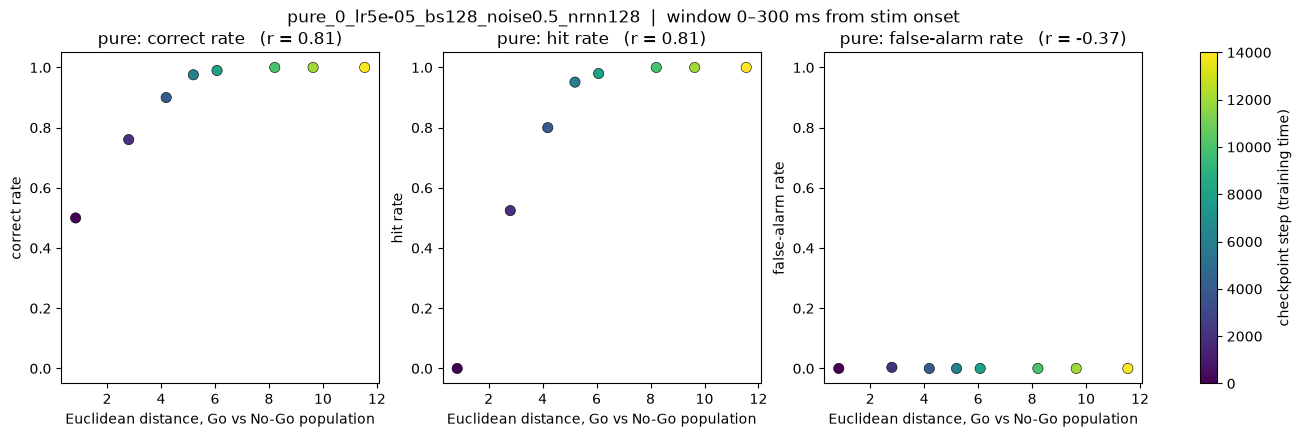

harmonic_0_lr5e-05_bs128_noise0.5_nrnn128: tasks=['harmonic']  window=(0, 300) ms -> steps [50, 80)
  step 0: no checkpoint_init.pkl, using a random network from config.json
  step      0 harmonic  hit=0.00 fa=0.00 correct=0.50 dist=0.906
  step   2000 harmonic  hit=0.71 fa=0.00 correct=0.85 dist=4.624
  step   4000 harmonic  hit=0.90 fa=0.00 correct=0.95 dist=6.478
  step   6000 harmonic  hit=0.98 fa=0.00 correct=0.99 dist=8.218
  step   8000 harmonic  hit=0.99 fa=0.00 correct=0.99 dist=10.762
  step  10000 harmonic  hit=1.00 fa=0.00 correct=1.00 dist=13.470
  step  12000 harmonic  hit=1.00 fa=0.00 correct=1.00 dist=17.075
  step  14000 harmonic  hit=1.00 fa=0.00 correct=1.00 dist=21.134


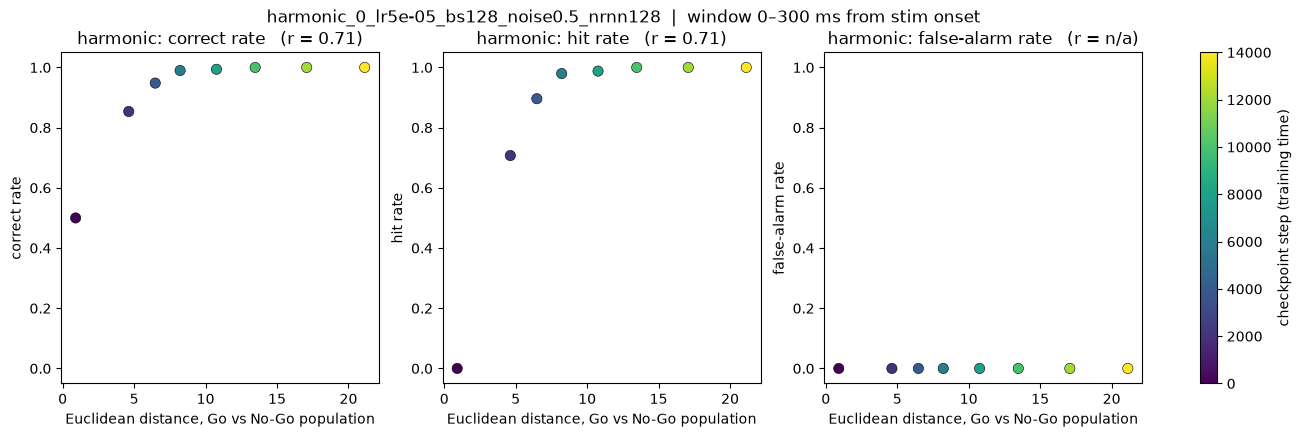

harmonic_0_lr5e-05_bs128_noise0.5_nrnn128: tasks=['harmonic']  window=(0, 300) ms -> steps [50, 80)
  step 0: using checkpoint_init.pkl
  step      0 harmonic  hit=0.66 fa=0.09 correct=0.78 dist=1.800
  step   2000 harmonic  hit=0.70 fa=0.00 correct=0.85 dist=3.402
  step   4000 harmonic  hit=0.73 fa=0.00 correct=0.87 dist=3.993
  step   6000 harmonic  hit=0.81 fa=0.00 correct=0.90 dist=4.572
  step   8000 harmonic  hit=0.76 fa=0.00 correct=0.88 dist=4.975
  step  10000 harmonic  hit=0.83 fa=0.00 correct=0.92 dist=5.035


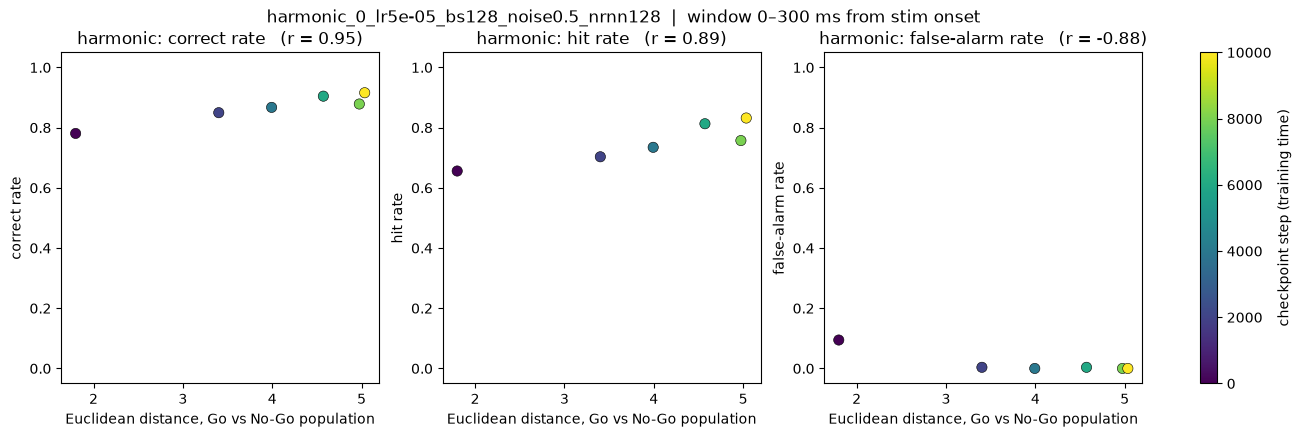

,task,step,hit,fa,correct,distance,mean_abs_dprime,label
0,pure,0,0.000000,0.000000,0.500000,0.834832,0.499180,PT
1,pure,2000,0.524390,0.003759,0.760315,2.802685,0.964278,PT
2,pure,4000,0.800000,0.000000,0.900000,4.190963,1.214421,PT
3,pure,6000,0.951220,0.000000,0.975610,5.199223,1.453774,PT
4,pure,8000,0.979757,0.000000,0.989879,6.076232,1.611278,PT
5,pure,10000,1.000000,0.000000,1.000000,8.214755,1.849032,PT
6,pure,12000,1.000000,0.000000,1.000000,9.635729,2.090791,PT
7,pure,14000,1.000000,0.000000,1.000000,11.547758,2.531464,PT
8,harmonic,0,0.000000,0.000000,0.500000,0.906225,0.630892,HCT
9,harmonic,2000,0.707317,0.000000,0.853659,4.623968,1.420377,HCT


In [6]:
# reload = True : load previously saved results (no recomputation)
# reload = False: re-simulate behaviour and distances, and save them
all_rows = []
for label, MODEL_DIR in MODEL_DIRs.items():
    if reload:
        rows = load_saved_rows(MODEL_DIR, window_ms=WINDOW_MS)
    else:
        rows = discrimination_vs_behavior(MODEL_DIR, window_ms=WINDOW_MS,
                                          n_trials=N_TRIALS, seed=SEED, show=True)
    for row in rows:
        row['label'] = label
    all_rows.extend(rows)
df = pd.DataFrame(all_rows)
df

In [10]:
labels

['PT', 'HCT', 'PT-HCT']

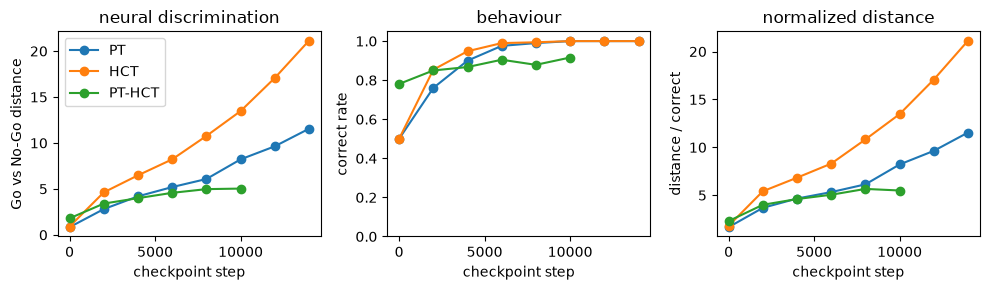

In [12]:
# distance and performance over training steps, one line per model (MODEL_DIRs key)
labels = list(df['label'].unique())
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for lab in labels:
    g = df[df['label'] == lab]
    axes[0].plot(g['step'], g['distance'], 'o-', label=lab)
    axes[1].plot(g['step'], g['correct'], 'o-', label=lab)
    axes[2].plot(g['step'], g['distance'] / g['correct'], 'o-', label=lab)
axes[0].set(xlabel='checkpoint step', ylabel='Go vs No-Go distance', title='neural discrimination')
axes[1].set(xlabel='checkpoint step', ylabel='correct rate', ylim=(0, 1.05), title='behaviour')
axes[2].set(xlabel='checkpoint step', ylabel='distance / correct', title='normalized distance')
axes[0].legend()
fig.tight_layout()
plt.show()

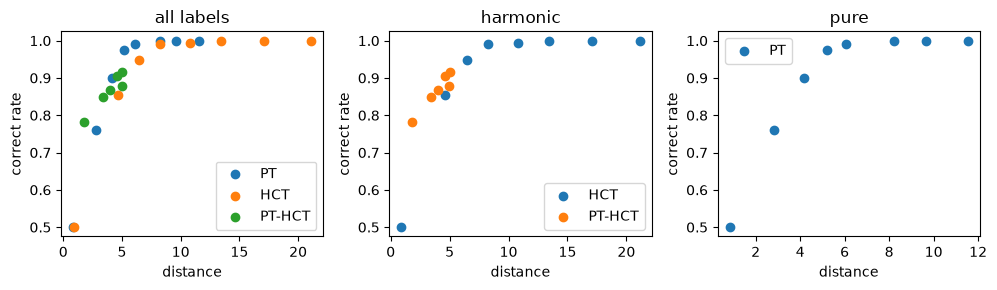

In [14]:
# combined plot of distance, correct rate, and normalized distance over training steps
# behavior over distance
labels = list(df['label'].unique())
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
# panel one: all labels combined
# panel two: all tasks from with harmonic
# panel three: all tasks from with pure
for lab in labels:
    g = df[df['label'] == lab]
    axes[0].scatter(g['distance'], g['correct'], label=lab)
    if 'HCT' in lab:
        axes[1].scatter(g['distance'], g['correct'], label=lab)
    else:
        axes[2].scatter(g['distance'], g['correct'], label=lab)
axes[0].set(xlabel='distance', ylabel='correct rate', title='all labels')
axes[1].set(xlabel='distance', ylabel='correct rate', title='harmonic')
axes[2].set(xlabel='distance', ylabel='correct rate', title='pure')
axes[0].legend()
axes[1].legend()
axes[2].legend()
fig.tight_layout()
plt.show()